# Python Data Quality Analysis

## Project Overview

This project uses Python, Pandas, NumPy and Matplotlib to create a sample sales dataset, inspect data quality, clean selected issues, validate sales calculations, identify potential price outliers and visualize the price distribution.

### Learning workflow

Each practical section follows: **Question → Code → Result → Interpretation → Insight**.

### Dataset

The dataset is generated in this notebook with 1,000 records and 9 columns. It includes intentionally introduced data-quality issues for practice.

**Important:** The dataset is synthetic. Findings describe this generated practice dataset, not a real business.

---


## 1. Import Libraries

Import NumPy and Pandas for data creation and manipulation, and Matplotlib for visualization.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 2. Create the Sample Dataset

Create a reproducible sample sales dataset. `np.random.seed(42)` makes the random values reproducible when the notebook is run from the beginning.


In [ ]:
np.random.seed(42)

n=1000

df = pd.DataFrame({
    'Order_ID' : [f"620{i:02d}" for i in range(1,n+1)],

    'Order_Date' : pd.to_datetime(
        np.random.choice(
            pd.date_range("2025-01-01","2025-12-31"),
            size = n
        )
    ),

    'Product' : np.random.choice(
        ['Laptop','Mouse','Keyboard','Monitor','Headphones'],
        size = n
    ),

    'Category' : np.random.choice(
        ['Electronics','Accessories','Audio'],
        size = n
    ),

    'Price' : np.random.randint(200,50001,size = n),

    'Quantity' : np.random.randint(1,11,size = n),

    'Region' : np.random.choice(
        ['North','South','East','West'],
        size = n
    ),

    'Payment_Method' : np.random.choice(
        ['UPI','Cash','Card','Netbanking'],
        size = n
    )
})
df['Sales'] = df['Price'] * df['Quantity']
df.head()

,Order_ID,Order_Date,Product,Category,Price,Quantity,Region,Payment_Method,Sales
0,62001,2025-04-13,Keyboard,Electronics,39312,9,North,UPI,353808
1,62002,2025-12-15,Keyboard,Electronics,38747,3,North,UPI,116241
2,62003,2025-09-28,Laptop,Electronics,28995,10,West,Cash,289950
3,62004,2025-04-17,Mouse,Electronics,21647,4,North,Card,86588
4,62005,2025-03-13,Mouse,Electronics,36798,9,North,Netbanking,331182


In [ ]:
print('Dataset shape :', df.shape)
print('Total rows :', len(df))
print('Total_columns :', len(df.columns))
df.info()

Dataset shape : (1000, 9)
Total rows : 1000
Total_columns : 9
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Order_ID        1000 non-null   object        
 1   Order_Date      1000 non-null   datetime64[ns]
 2   Product         1000 non-null   object        
 3   Category        1000 non-null   object        
 4   Price           1000 non-null   int64         
 5   Quantity        1000 non-null   int64         
 6   Region          1000 non-null   object        
 7   Payment_Method  1000 non-null   object        
 8   Sales           1000 non-null   int64         
dtypes: datetime64[ns](1), int64(3), object(5)
memory usage: 70.4+ KB


## 3. Introduce Data-Quality Issues

Intentionally add missing values, duplicate records, inconsistent text, invalid numeric values, an incorrect data type, an extreme price, an invalid date and incorrect Sales values. These issues provide examples to investigate during cleaning.


In [ ]:
# 1. Missing values
df.loc[10, "Product"] = np.nan
df.loc[20, "Price"] = np.nan
df.loc[30, "Quantity"] = np.nan
df.loc[40, "Region"] = np.nan
df.loc[60, "Payment_Method"] = np.nan
df.loc[160, "Sales"] = np.nan

# 2. Duplicate complete records
df.loc[50] = df.loc[49].copy()
df.loc[150] = df.loc[149].copy()

# 3. Inconsistent text
df.loc[70, "Product"] = " laptop "
df.loc[80, "Region"] = "south "
df.loc[170, "Category"] = "Electonic"

# 4. Invalid numeric values
df.loc[90, "Price"] = -100
df.loc[91, "Price"] = 0
df.loc[100, "Quantity"] = -5
df.loc[101, "Quantity"] = 0

# 5. Incorrect data type
df["Price"] = df["Price"].astype(object)
df.loc[110, "Price"] = "unknown"

# 6. Suspicious extreme value
df.loc[130, "Price"] = 999999

# 7. Invalid date
df["Order_Date"] = df["Order_Date"].astype(object)
df.loc[140, "Order_Date"] = "not_a_date"

# 8. Incorrect sales calculations
df.loc[120, "Sales"] = 999999
df.loc[121, "Sales"] = 1

print("Dataset created with intentional quality issues.")
print("Shape:", df.shape)

df.head()

Dataset created with intentional quality issues.
Shape: (1000, 9)


,Order_ID,Order_Date,Product,Category,Price,Quantity,Region,Payment_Method,Sales
0,62001,2025-04-13 00:00:00,Keyboard,Electronics,39312.0,9.0,North,UPI,353808.0
1,62002,2025-12-15 00:00:00,Keyboard,Electronics,38747.0,3.0,North,UPI,116241.0
2,62003,2025-09-28 00:00:00,Laptop,Electronics,28995.0,10.0,West,Cash,289950.0
3,62004,2025-04-17 00:00:00,Mouse,Electronics,21647.0,4.0,North,Card,86588.0
4,62005,2025-03-13 00:00:00,Mouse,Electronics,36798.0,9.0,North,Netbanking,331182.0


## 4. Initial Data Inspection

Inspect dataset dimensions, data types, missing values and duplicate records before cleaning.


In [ ]:
print('Missing values :')
print(df.isnull().sum())
print('\nDuplicate rows :',df.duplicated().sum())
print('\nDataset shape :',df.shape)

Missing values :
Order_ID          0
Order_Date        0
Product           1
Category          0
Price             1
Quantity          1
Region            1
Payment_Method    1
Sales             1
dtype: int64

Duplicate rows : 2

Dataset shape : (1000, 9)


In [ ]:
print(df.dtypes)

Order_ID           object
Order_Date         object
Product            object
Category           object
Price              object
Quantity          float64
Region             object
Payment_Method     object
Sales             float64
dtype: object


In [ ]:
price_check = pd.to_numeric(df['Price'],errors='coerce')
quantity_check = pd.to_numeric(df['Quantity'],errors='coerce')
date_check = pd.to_datetime(df['Order_Date'],errors='coerce')
print('Price check :',price_check.isna().sum())
print('negative :',(price_check < 0).sum())

Price check : 2
negative : 1


In [ ]:
print(df.dtypes)

Order_ID           object
Order_Date         object
Product            object
Category           object
Price              object
Quantity          float64
Region             object
Payment_Method     object
Sales             float64
dtype: object


In [ ]:
# Check data types
print(df.dtypes)

# Convert values temporarily for validation
price_check = pd.to_numeric(df["Price"], errors="coerce")
quantity_check = pd.to_numeric(df["Quantity"], errors="coerce")

# Count invalid and suspicious values
print("\nNon-numeric prices:", price_check.isna().sum())
print("Negative prices:", (price_check < 0).sum())
print("Zero prices:", (price_check == 0).sum())
print("Negative quantities:", (quantity_check < 0).sum())
print("Zero quantities:", (quantity_check == 0).sum())

# Check invalid dates
date_check = pd.to_datetime(df["Order_Date"], errors="coerce")
print("Invalid dates:", date_check.isna().sum())

Order_ID           object
Order_Date         object
Product            object
Category           object
Price              object
Quantity          float64
Region             object
Payment_Method     object
Sales             float64
dtype: object

Non-numeric prices: 2
Negative prices: 1
Zero prices: 1
Negative quantities: 1
Zero quantities: 1
Invalid dates: 1


In [ ]:
price_check = pd.to_numeric(df['Price'],errors='coerce')
quantity_check = pd.to_numeric(df['Quantity'],errors='coerce')
expected_sales = price_check * quantity_check
sales_check = pd.to_numeric(df['Sales'],errors='coerce')
mismatch = (
    expected_sales.notna()&
    sales_check.notna()&
    ~np.isclose(
        expected_sales.fillna(0),
        sales_check.fillna(0)
    )
)
print(mismatch.sum())
df.loc[mismatch, ["Order_ID", "Price", "Quantity", "Sales"]]

7


,Order_ID,Price,Quantity,Sales
90,62091,-100.0,3.0,73119.0
91,62092,0.0,2.0,11148.0
100,620101,1692.0,-5.0,8460.0
101,620102,30662.0,0.0,275958.0
120,620121,32374.0,3.0,999999.0
121,620122,34415.0,4.0,1.0
130,620131,999999,9.0,209988.0


In [ ]:
df.to_csv('Sales_Data_Analysis_Project.csv',index=False)

In [ ]:
# from google.colab import files
# files.download('Sales_Data_Analysis_Project.csv')

## 5. Explore Missing Values and Duplicates

Inspect rows containing missing values and examine duplicate records before removing exact duplicates.


In [ ]:
missing_rows = df[df.isna().any(axis=1)]
print(len(missing_rows))
missing_rows.set_index('Order_ID')

6


,Order_Date,Product,Category,Price,Quantity,Region,Payment_Method,Sales
Order_ID,,,,,,,,
62011,2025-11-27 00:00:00,NaN,Accessories,47446.0,1.0,East,Card,47446.0
62021,2025-10-21 00:00:00,Headphones,Accessories,NaN,1.0,South,Card,33360.0
62031,2025-02-28 00:00:00,Keyboard,Audio,6901.0,NaN,East,UPI,6901.0
62041,2025-11-16 00:00:00,Headphones,Audio,12309.0,9.0,NaN,Card,110781.0
62061,2025-03-22 00:00:00,Keyboard,Audio,28565.0,7.0,North,NaN,199955.0
620161,2025-02-14 00:00:00,Keyboard,Audio,28569.0,3.0,West,Card,NaN


In [ ]:
duplicate_records = df[df.duplicated()]
duplicate_records

,Order_ID,Order_Date,Product,Category,Price,Quantity,Region,Payment_Method,Sales
50,62050,2025-11-12 00:00:00,Laptop,Electronics,34718.0,4.0,North,Card,138872.0
150,620150,2025-01-29 00:00:00,Mouse,Accessories,46771.0,9.0,West,Card,420939.0


In [ ]:
# Cell 12: Find duplicate records

duplicate_rows = df[df.duplicated()]

print("Total duplicate rows:", df.duplicated().sum())

print("\nDuplicate records:")
print(duplicate_rows)

Total duplicate rows: 2

Duplicate records:
    Order_ID           Order_Date Product     Category    Price  Quantity  \
50     62050  2025-11-12 00:00:00  Laptop  Electronics  34718.0       4.0   
150   620150  2025-01-29 00:00:00   Mouse  Accessories  46771.0       9.0   

    Region Payment_Method     Sales  
50   North           Card  138872.0  
150   West           Card  420939.0  


In [ ]:
# Cell 13: Compare duplicate rows with their originals

print("Original row for duplicate at index 50:")
print(df.loc[49])

print("\nDuplicate row at index 50:")
print(df.loc[50])

print("\nOriginal row for duplicate at index 150:")
print(df.loc[149])

print("\nDuplicate row at index 150:")
print(df.loc[150])

Original row for duplicate at index 50:
Order_ID                        62050
Order_Date        2025-11-12 00:00:00
Product                        Laptop
Category                  Electronics
Price                         34718.0
Quantity                          4.0
Region                          North
Payment_Method                   Card
Sales                        138872.0
Name: 49, dtype: object

Duplicate row at index 50:
Order_ID                        62050
Order_Date        2025-11-12 00:00:00
Product                        Laptop
Category                  Electronics
Price                         34718.0
Quantity                          4.0
Region                          North
Payment_Method                   Card
Sales                        138872.0
Name: 50, dtype: object

Original row for duplicate at index 150:
Order_ID                       620150
Order_Date        2025-01-29 00:00:00
Product                         Mouse
Category                  Accessories
Price 

## 6. Clean the Dataset

Create a separate cleaned copy, remove exact duplicate rows, standardize text values, convert numeric and date columns, and inspect remaining missing and invalid values.


In [ ]:
df_clean = df.drop_duplicates().copy()
print(df.shape)
print(df_clean.shape)
print(df_clean.duplicated().sum())

(1000, 9)
(998, 9)
0


In [ ]:
print(df_clean['Product'].unique())
print(df_clean['Region'].unique())
print(df_clean['Category'].unique())
print(df_clean['Payment_Method'].unique())

['Keyboard' 'Laptop' 'Mouse' 'Headphones' 'Monitor' nan ' laptop ']
['North' 'West' 'East' 'South' nan 'south ']
['Electronics' 'Audio' 'Accessories' 'Electonic']
['UPI' 'Cash' 'Card' 'Netbanking' nan]


In [ ]:
df_clean['Product'] = df_clean['Product'].str.strip().str.title()
df_clean['Region'] = df_clean['Region'].str.strip().str.title()
df_clean['Category'] = df_clean['Category'].replace({
    'Electonic' : 'Electronics'
})
df_clean['Payment_Method'] = df_clean['Payment_Method'].replace({
    'Netbanking' : 'Net banking'
})

In [ ]:
print(df_clean['Product'].unique())
print(df_clean['Region'].unique())
print(df_clean['Category'].unique())
print(df_clean['Payment_Method'].unique())

['Keyboard' 'Laptop' 'Mouse' 'Headphones' 'Monitor' nan]
['North' 'West' 'East' 'South' nan]
['Electronics' 'Audio' 'Accessories']
['UPI' 'Cash' 'Card' 'Net banking' nan]


In [ ]:
df_clean['Price'] = pd.to_numeric(df_clean['Price'],errors='coerce')

In [ ]:
df_clean[df_clean['Price']<=0]
df_clean[df_clean['Quantity']<=0][['Order_ID','Quantity']]

,Order_ID,Quantity
100,620101,-5.0
101,620102,0.0


In [ ]:
print(df_clean.dtypes)

Order_ID           object
Order_Date         object
Product            object
Category           object
Price             float64
Quantity          float64
Region             object
Payment_Method     object
Sales             float64
dtype: object


In [ ]:
df_clean['Order_Date'] = pd.to_datetime(df_clean['Order_Date'],errors = 'coerce')

In [ ]:
print(df_clean.dtypes)

Order_ID                  object
Order_Date        datetime64[ns]
Product                   object
Category                  object
Price                    float64
Quantity                 float64
Region                    object
Payment_Method            object
Sales                    float64
dtype: object


In [ ]:
print(df_clean.loc[df_clean['Order_Date'].isna(),['Order_ID','Order_Date']])

    Order_ID Order_Date
140   620141        NaT


### 6.1 Missing-Value Review

Count missing values by column and inspect the affected records. Only fill a missing value when the available fields and an explicitly stated rule support the calculation.


In [ ]:
missing_count = df_clean.isna().sum()

print(missing_count[missing_count > 0])

Order_Date        1
Product           1
Price             2
Quantity          1
Region            1
Payment_Method    1
Sales             1
dtype: int64


In [ ]:
missing_rows = df_clean[df_clean.isna().any(axis=1)].set_index('Order_ID')
print(missing_rows.to_string())

         Order_Date     Product     Category    Price  Quantity Region Payment_Method     Sales
Order_ID                                                                                       
62011    2025-11-27         NaN  Accessories  47446.0       1.0   East           Card   47446.0
62021    2025-10-21  Headphones  Accessories      NaN       1.0  South           Card   33360.0
62031    2025-02-28    Keyboard        Audio   6901.0       NaN   East            UPI    6901.0
62041    2025-11-16  Headphones        Audio  12309.0       9.0    NaN           Card  110781.0
62061    2025-03-22    Keyboard        Audio  28565.0       7.0  North            NaN  199955.0
620111   2025-05-15     Monitor  Electronics      NaN       7.0   West    Net banking  140700.0
620141          NaT    Keyboard  Electronics  18062.0       1.0   West           Card   18062.0
620161   2025-02-14    Keyboard        Audio  28569.0       3.0   West           Card       NaN


In [ ]:
missing_sales = df_clean['Sales'].isna()
df_clean.loc[missing_sales,'Sales'] = df_clean.loc[missing_sales,'Price'] * df_clean.loc[missing_sales,'Quantity']
print(df_clean.loc[
    missing_sales,
    ["Order_ID", "Price", "Quantity", "Sales"]
])

    Order_ID    Price  Quantity    Sales
160   620161  28569.0       3.0  85707.0


In [ ]:
print("Missing Sales:", df_clean["Sales"].isna().sum())

print(df_clean.loc[
    df_clean["Order_ID"] == "ORD0161",
    ["Order_ID", "Price", "Quantity", "Sales"]
])

Missing Sales: 0
Empty DataFrame
Columns: [Order_ID, Price, Quantity, Sales]
Index: []


In [ ]:
missing_rows = df_clean[df_clean.isna().any(axis=1)].set_index('Order_ID')
print(missing_rows.to_string())

         Order_Date     Product     Category    Price  Quantity Region Payment_Method     Sales
Order_ID                                                                                       
62011    2025-11-27         NaN  Accessories  47446.0       1.0   East           Card   47446.0
62021    2025-10-21  Headphones  Accessories      NaN       1.0  South           Card   33360.0
62031    2025-02-28    Keyboard        Audio   6901.0       NaN   East            UPI    6901.0
62041    2025-11-16  Headphones        Audio  12309.0       9.0    NaN           Card  110781.0
62061    2025-03-22    Keyboard        Audio  28565.0       7.0  North            NaN  199955.0
620111   2025-05-15     Monitor  Electronics      NaN       7.0   West    Net banking  140700.0
620141          NaT    Keyboard  Electronics  18062.0       1.0   West           Card   18062.0


### 6.2 Validate Price and Quantity

Identify zero and negative values in Price and Quantity. These are treated as invalid for this practice dataset and are kept for investigation rather than silently changed.


In [ ]:
invalid_prices = df_clean[
    df_clean["Price"] <= 0
]

print(invalid_prices[["Order_ID", "Price"]])

   Order_ID  Price
90    62091 -100.0
91    62092    0.0


In [ ]:
invalid_quantity = df_clean[
    df_clean["Quantity"] <= 0
]

print(invalid_quantity[["Order_ID", "Quantity"]])

    Order_ID  Quantity
100   620101      -5.0
101   620102       0.0


## 7. Validate Sales Calculations

Compare recorded Sales with `Price × Quantity`. This validation assumes that the dataset's Sales rule is exactly Price multiplied by Quantity, with no discounts, taxes or other adjustments.


In [ ]:
df_clean['Expected_Sales'] = df_clean['Price'] * df_clean['Quantity']
sales_mismatch = df_clean[df_clean['Expected_Sales'].notna()&
                 df_clean['Sales'].notna()&
                 (df_clean['Expected_Sales'] != df_clean['Sales'])]

print(sales_mismatch[
    ["Order_ID", "Price", "Quantity", "Sales", "Expected_Sales"]
])

    Order_ID     Price  Quantity     Sales  Expected_Sales
90     62091    -100.0       3.0   73119.0          -300.0
91     62092       0.0       2.0   11148.0             0.0
100   620101    1692.0      -5.0    8460.0         -8460.0
101   620102   30662.0       0.0  275958.0             0.0
120   620121   32374.0       3.0  999999.0         97122.0
121   620122   34415.0       4.0       1.0        137660.0
130   620131  999999.0       9.0  209988.0       8999991.0


In [ ]:
sales_error = df_clean[df_clean["Order_ID"].isin(["620121","620122"])]
print(sales_error[
    ["Order_ID", "Price", "Quantity", "Sales", "Expected_Sales"]
])

    Order_ID    Price  Quantity     Sales  Expected_Sales
120   620121  32374.0       3.0  999999.0         97122.0
121   620122  34415.0       4.0       1.0        137660.0


In [ ]:
df_clean.loc[
    df_clean['Order_ID'].isin(['620121','620122']),'Sales'] = df_clean.loc[
        df_clean['Order_ID'].isin(['620121','620122']),'Expected_Sales']

print(df_clean.loc[
    df_clean["Order_ID"].isin(["620121", "620122"]),
    ["Order_ID", "Price", "Quantity", "Sales"]
])

    Order_ID    Price  Quantity     Sales
120   620121  32374.0       3.0   97122.0
121   620122  34415.0       4.0  137660.0


In [ ]:
sales_mismatch = df_clean[
    df_clean["Sales"].notna()
    & df_clean["Expected_Sales"].notna()
    & (df_clean["Sales"] != df_clean["Expected_Sales"])
]

print(sales_mismatch[
    ["Order_ID", "Price", "Quantity", "Sales", "Expected_Sales"]
])

print("Remaining mismatches:", len(sales_mismatch))

    Order_ID     Price  Quantity     Sales  Expected_Sales
90     62091    -100.0       3.0   73119.0          -300.0
91     62092       0.0       2.0   11148.0             0.0
100   620101    1692.0      -5.0    8460.0         -8460.0
101   620102   30662.0       0.0  275958.0             0.0
130   620131  999999.0       9.0  209988.0       8999991.0
Remaining mismatches: 5


In [ ]:
print(df_clean.loc[df_clean['Order_ID']== '620131',["Order_ID", "Product", "Category", "Price", "Quantity", "Sales"]])

    Order_ID     Product     Category     Price  Quantity     Sales
130   620131  Headphones  Electronics  999999.0       9.0  209988.0


In [ ]:
print(df.loc[df['Order_ID']=='620131'].to_string())

    Order_ID           Order_Date     Product     Category   Price  Quantity Region Payment_Method     Sales
130   620131  2025-09-12 00:00:00  Headphones  Electronics  999999       9.0  North            UPI  209988.0


In [ ]:
invalid_records = df_clean[(df_clean['Price']<=0) | (df_clean['Quantity']<=0)]
print(invalid_records[['Order_ID','Price','Quantity','Sales']].to_string())

    Order_ID    Price  Quantity     Sales
90     62091   -100.0       3.0   73119.0
91     62092      0.0       2.0   11148.0
100   620101   1692.0      -5.0    8460.0
101   620102  30662.0       0.0  275958.0


### 7.1 Create an Invalid-Input Report

Combine records with non-positive Price or Quantity and label the issue. Missing inputs are reviewed separately.


In [ ]:
price_issues = df_clean[df_clean['Price'] <= 0].copy()
price_issues['Issues'] = 'Invalid Price'

quantity_issues = df_clean[df_clean['Quantity'] <= 0].copy()
quantity_issues['Issues'] = 'Invalid Quantity'

invalid_report = pd.concat([
    price_issues,
    quantity_issues
])

print(invalid_report[['Order_ID','Price','Quantity','Sales','Issues']].to_string())

    Order_ID    Price  Quantity     Sales            Issues
90     62091   -100.0       3.0   73119.0     Invalid Price
91     62092      0.0       2.0   11148.0     Invalid Price
100   620101   1692.0      -5.0    8460.0  Invalid Quantity
101   620102  30662.0       0.0  275958.0  Invalid Quantity


## 8. Detect Potential Price Outliers with Tukey's Rule

Use positive, non-missing Price values to calculate Q1, Q3 and IQR. The 1.5 × IQR rule identifies potential outliers; it does not prove that a value is an error.


In [ ]:
valid_prices = df_clean.loc[df_clean['Price']>0,'Price']
Q1 = valid_prices.quantile(0.25)
Q3 = valid_prices.quantile(0.75)
IQR = Q3 - Q1

lower_bound = round(Q1 -(1.5 * IQR),2)
upper_bound = round(Q3 +(1.5 * IQR),2)

outlier = valid_prices[(valid_prices < lower_bound) | (valid_prices > upper_bound)]

print(Q1)
print(Q3)
print(IQR)
print(lower_bound)
print(upper_bound)
print(outlier)

12318.0
36796.75
24478.75
-24400.12
73514.88
130    999999.0
Name: Price, dtype: float64


In [ ]:
print(df_clean.loc[130])

Order_ID                       620131
Order_Date        2025-09-12 00:00:00
Product                    Headphones
Category                  Electronics
Price                        999999.0
Quantity                          9.0
Region                          North
Payment_Method                    UPI
Sales                        209988.0
Expected_Sales              8999991.0
Name: 130, dtype: object


In [ ]:
print(df.loc[130])

Order_ID                       620131
Order_Date        2025-09-12 00:00:00
Product                    Headphones
Category                  Electronics
Price                          999999
Quantity                          9.0
Region                          North
Payment_Method                    UPI
Sales                        209988.0
Name: 130, dtype: object


### 8.1 Investigate the Potential Outlier

Inspect the record identified by Tukey's rule and compare it with the original dataset. Keep unusual values flagged until reliable source information supports a correction.


Order 620131 was identified as a potential price outlier using Tukey's 1.5 × IQR rule. Its recorded sales value also does not match the expected sales calculation. Both values were present in the original dataset, so the record was flagged for further investigation rather than modified without evidence

### 8.2 Review Sales Mismatches with Valid Inputs

Check whether the mismatched records have positive Price and Quantity values. Recalculation is only appropriate when the stated Sales formula is confirmed.


In [ ]:
valid_inputs = (
    (df_clean["Price"] > 0) &
    (df_clean["Quantity"] > 0)
)

print(
    df_clean.loc[
        sales_mismatch.index,
        ["Order_ID", "Price", "Quantity", "Sales", "Expected_Sales"]
    ].assign(
        Valid_Inputs=valid_inputs.loc[sales_mismatch.index]
    )
)

    Order_ID     Price  Quantity     Sales  Expected_Sales  Valid_Inputs
90     62091    -100.0       3.0   73119.0          -300.0         False
91     62092       0.0       2.0   11148.0             0.0         False
100   620101    1692.0      -5.0    8460.0         -8460.0         False
101   620102   30662.0       0.0  275958.0             0.0         False
130   620131  999999.0       9.0  209988.0       8999991.0          True


In [ ]:
df_clean.loc[130, "Sales"] = df_clean.loc[130, "Expected_Sales"]

print(df_clean.loc[130, ["Order_ID", "Sales", "Expected_Sales"]])

Order_ID             620131
Sales             8999991.0
Expected_Sales    8999991.0
Name: 130, dtype: object


In [ ]:
df_clean.loc[130, ["Order_ID", "Sales", "Expected_Sales"]]

,130
Order_ID,620131
Sales,8999991.0
Expected_Sales,8999991.0


In [ ]:
# Recalculate Expected_Sales for validation
# Missing Price or Quantity produces a missing Expected_Sales value.
df_clean["Expected_Sales"] = df_clean["Price"] * df_clean["Quantity"]

# Compare only rows where both Sales and Expected_Sales are available
sales_mismatch = df_clean[
    df_clean["Sales"].notna()
    & df_clean["Expected_Sales"].notna()
    & (df_clean["Sales"] != df_clean["Expected_Sales"])
]

print(sales_mismatch[
    ["Order_ID", "Price", "Quantity", "Sales", "Expected_Sales"]
])


### 8.3 Separate Missing and Invalid Inputs

Report missing inputs separately from zero or negative inputs. Do not infer replacement values without evidence.


In [ ]:
# Find records with missing Price or Quantity
missing_inputs = df_clean[
    df_clean["Price"].isna() | df_clean["Quantity"].isna()
]

print("Records with missing inputs:")
print(missing_inputs.to_string(), "\n")

# Find records with invalid (zero or negative) Price or Quantity
invalid_inputs = df_clean[
    (df_clean["Price"] <= 0) | (df_clean["Quantity"] <= 0)
]

print("Records with invalid inputs:")
print(invalid_inputs.to_string())


Interpretation:

The Sales validation identified seven records with missing or invalid Price and Quantity values. These records were retained for further investigation because their correct values cannot be established from the available data alone.

Insight:

Sales validation depends on the quality of its input columns. Missing or invalid Price and Quantity values can prevent reliable Sales verification.

### 8.4 Final Sales Validation

Check for remaining Sales mismatches only where Price and Quantity are positive. The check should also exclude missing Sales and Expected_Sales values.


In [ ]:
sales_mismatch = df_clean[
    (df_clean['Price']>0) &
    (df_clean['Quantity']>0) &
    (df_clean['Sales'] != df_clean['Expected_Sales'])
]
print(sales_mismatch.to_string())



Empty DataFrame
Columns: [Order_ID, Order_Date, Product, Category, Price, Quantity, Region, Payment_Method, Sales, Expected_Sales]
Index: []


Result: No Sales mismatches were found among records with positive, non-missing Price and Quantity.

Interpretation: The Sales calculation validation passed for the records meeting these input conditions.

Insight: Validating input columns before checking calculated values helps prevent misleading results.

## 9. Matplotlib Boxplot Visualization

Create a vertical boxplot to view the distribution of valid positive prices. Use an axis limit to zoom into the central price range; this changes the visible chart range, not the underlying data.


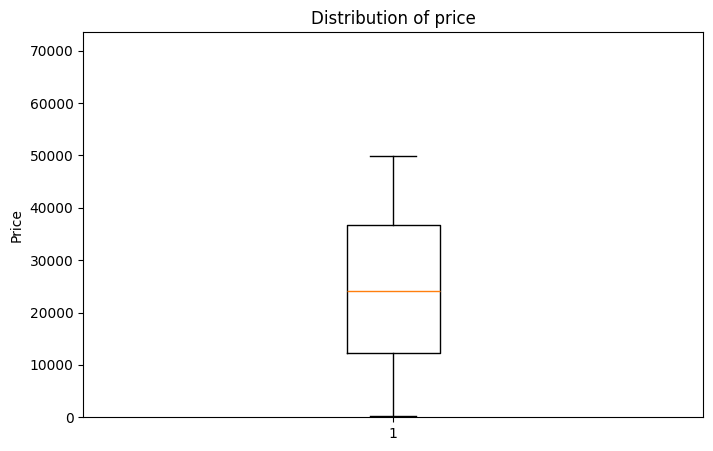

In [ ]:
# for vertical understanding

plt.figure(figsize=(8,5))
plt.boxplot(valid_prices)
plt.ylim(0,upper_bound)
plt.title('Distribution of price')
plt.ylabel('Price')
plt.show()

### 9.1 Horizontal Boxplot and Reference Boundaries

Change the orientation and add quartile labels and Tukey boundary reference lines.


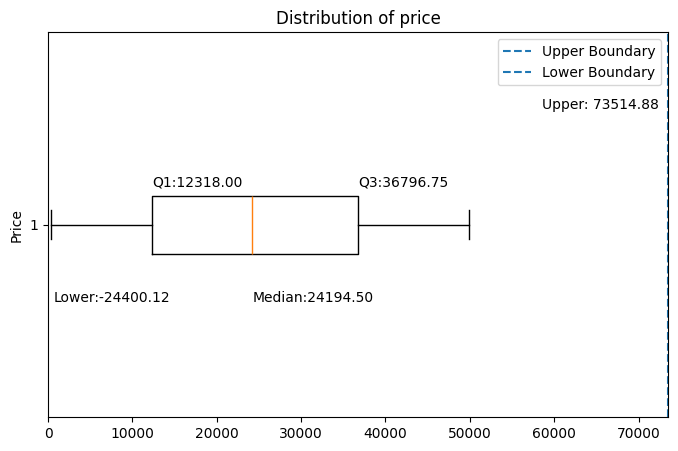

In [ ]:
# for horizontal analysis

plt.figure(figsize=(8,5))
plt.boxplot(valid_prices,vert=False)
plt.text(Q1,1.1,f"Q1:{Q1:.2f}")
plt.text(Q3,1.1,f"Q3:{Q3:.2f}")
plt.text(valid_prices.median(),0.8,f"Median:{valid_prices.median():.2f}")
plt.xlim(0,upper_bound)
plt.title('Distribution of price')
plt.ylabel('Price')
plt.axvline(upper_bound, linestyle="--", label="Upper Boundary")
plt.text(
    upper_bound - 15000,
    1.3,
    f"Upper: {upper_bound:.2f}"
)
plt.axvline(lower_bound,linestyle="--",label="Lower Boundary")
plt.text(lower_bound + 25000,0.8,f"Lower:{lower_bound:.2f}")
plt.legend()
plt.show()

### 9.2 Highlight Potential Outliers

Use a scatter point to emphasize the value or values identified as potential outliers.


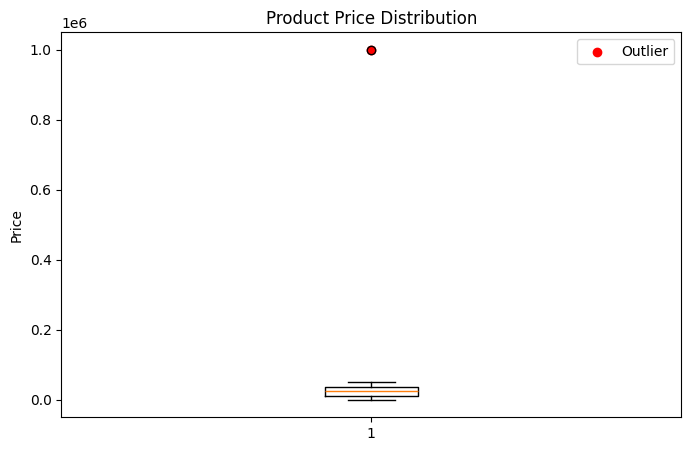

In [ ]:
plt.figure(figsize=(8, 5))

plt.boxplot(valid_prices)

plt.scatter(
    1,
    outlier.values,
    color="red",
    label="Outlier"
)

plt.title("Product Price Distribution")
plt.ylabel("Price")
plt.legend()

plt.show()

### 9.3 Customize the Boxplot

Use `patch_artist=True` to fill the box and customize its appearance.


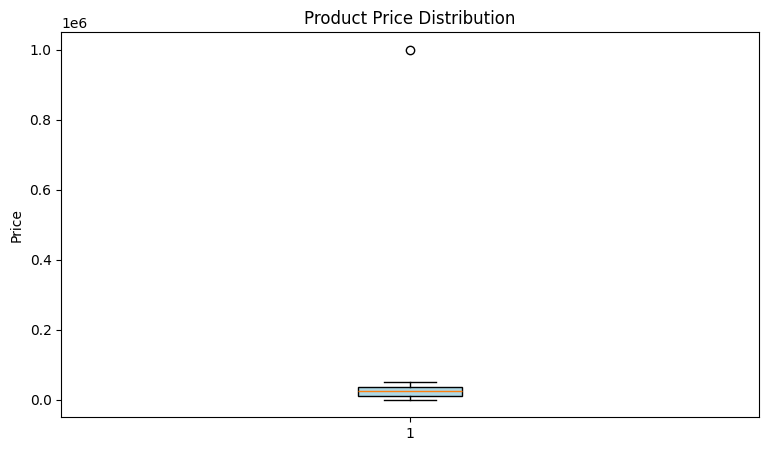

In [ ]:
plt.figure(figsize=(9, 5))

box = plt.boxplot(
    valid_prices,
    patch_artist = True
)
# change box colour
for item in box['boxes']:
  item.set_facecolor('lightblue')
plt.title("Product Price Distribution")
plt.ylabel("Price")

plt.show()

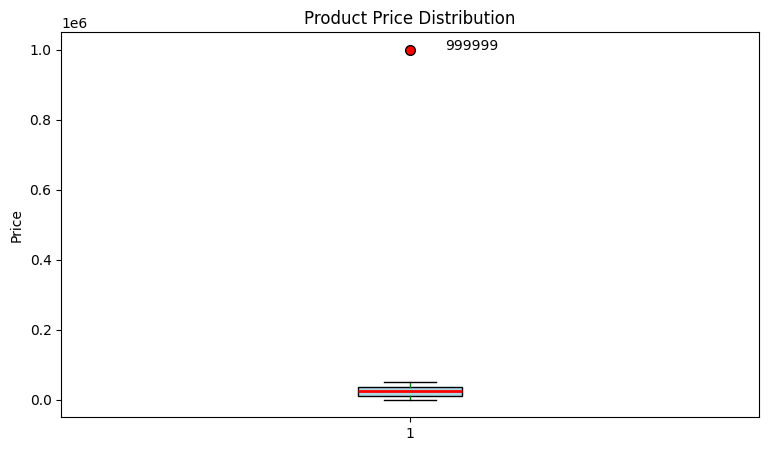

In [ ]:
plt.figure(figsize=(9, 5))

box = plt.boxplot(
    valid_prices,
    patch_artist=True
)

# Box color
for item in box["boxes"]:
    item.set_facecolor("lightblue")

# Median color
for item in box["medians"]:
    item.set_color("red")
    item.set_linewidth(2)

# Whisker color
for item in box["whiskers"]:
    item.set_color("green")

# Outlier appearance
for item in box["fliers"]:
    item.set_markerfacecolor("red")
    item.set_markeredgecolor("black")
    item.set_markersize(7)

for value in outlier:
    plt.text(1.05, value, f"{value:.0f}")


plt.title("Product Price Distribution")
plt.ylabel("Price")

plt.show()

### 9.4 Final Customized Boxplot

Combine the box fill, median, whisker and outlier styling with Q1, median and Q3 labels. The zoomed view hides values outside the displayed range but does not remove them from the data.


In [ ]:
plt.figure(figsize=(10, 6))

# Create the boxplot
box = plt.boxplot(valid_prices, patch_artist=True)

# Customize the box
for item in box["boxes"]:
    item.set_facecolor("lightblue")

# Customize the median line
for item in box["medians"]:
    item.set_color("red")
    item.set_linewidth(2)

# Customize whiskers
for item in box["whiskers"]:
    item.set_color("green")

# Customize outlier markers
for item in box["fliers"]:
    item.set_markerfacecolor("red")
    item.set_markeredgecolor("black")
    item.set_markersize(7)

# Calculate median explicitly for this cell
median = valid_prices.median()

# Label quartiles and median
plt.text(1.08, Q1, f"Q1: {Q1:.2f}")
plt.text(1.08, median, f"Median: {median:.2f}")
plt.text(1.08, Q3, f"Q3: {Q3:.2f}")

# Zoom the visible price range; this does not remove outliers
plt.ylim(0, upper_bound)

plt.title("Product Price Distribution")
plt.ylabel("Price")
plt.show()


## 10. Project Summary

This notebook demonstrates a practical data-quality workflow: dataset inspection, duplicate removal, text standardization, type conversion, missing and invalid value review, Sales validation, IQR-based potential outlier detection and Matplotlib boxplot visualization.

### Limitations and decisions

- The dataset is synthetic and contains deliberately inserted issues.
- Missing or invalid inputs are not automatically replaced without evidence.
- The Sales validation uses the stated `Price × Quantity` rule. Confirm this rule before applying it to real business data.
- The value identified as a potential outlier is retained and flagged for investigation rather than automatically deleted.
